# Project Data Mining

## Shahab Esfandiar 40301644

# *Article : Next Day Wildfire Spread: A Machine Learning Dataset to Predict Wildfire Spreading From Remote Sensing Data*

---

## <span style="color: goldenrod;">1. Abstract</span>  
The authors present **Next Day Wildfire Spread**, a dataset of 18,545 paired fire‐mask samples at 1 km resolution, each enriched with eleven environmental and human‐influence variables for one-day-ahead wildfire-spread prediction. Their convolutional autoencoder achieves an **AUC-PR** of **28.4%**, outperforming logistic regression (22%) and random forest (25%) baselines.

---

## <span style="color: goldenrod;">2. Introduction</span>  
Wildfires devastate millions of hectares, endanger communities, and contribute to ~300 000 premature deaths via smoke inhalation. In 2019, over 775 000 U.S. homes were classified at “High” or “Very High” fire risk. One-day lead-time forecasts enable fire managers to:  
- Pre-stage personnel and aircraft  
- Design containment lines and controlled burns  
- Shut off vulnerable infrastructure (e.g., power lines)  

This work fills a gap by releasing a large public dataset and modular Google Earth Engine extraction code. 

---

## <span style="color: goldenrod;">3. Dataset Aggregation</span>  

The dataset was assembled using Google Earth Engine for the continental U.S. from 2012 to 2020. Researchers extracted 64 × 64 km windows where the fire-affected area changed between consecutive days, resulting in 18,545 valid samples. Each sample integrates daily fire classification from MODIS/Terra with meteorological, topographical, vegetation, drought, and population data, all resampled to a consistent 1 km grid.
Using Google Earth Engine (2012–2020, CONUS), 64 × 64 km windows with day-to-day fire-area changes yielded **18 545** samples. Inputs:

| Source                        | Variables                                  | Resolution & Interval               |
|-------------------------------|--------------------------------------------|-------------------------------------|
| **MODIS/Terra (MOD14A1)**     | Fire / No-fire / Uncertain mask            | 1 km, daily                         |
| **GRIDMET**                   | Min/max temperature, humidity, wind, rain  | 4 km, daily                         |
| **GRIDMET Drought**           | Drought index                              | 4 km, every 5 days                  |
| **VIIRS VNP13A1 (NDVI)**      | Vegetation index                           | 0.5 km, 8-day composite             |
| **SRTM**                      | Elevation                                  | 30 m → aggregated to 1 km           |
| **GPWv4**                     | Population density                         | 1 km, 5-year intervals              |


All layers resampled to **1 km** grid and split **80% train / 10% val / 10% test**

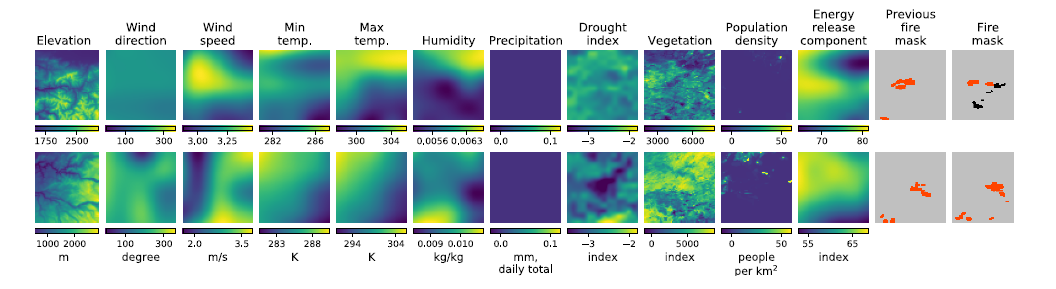

---

## <span style="color: goldenrod;">4. Data Preprocessing</span>   
1. **Clipping & Outlier Removal**  
   - Each feature limited to its physical range or percentiles [0.1, 99.9].  
2. **Normalization**  
   - Zero-mean, unit-variance scaling (training-set statistics).  
3. **Data Augmentation**  
   - Random **32 × 32** crops from each 64 × 64 window.  
   - Random 90° rotations and flips 

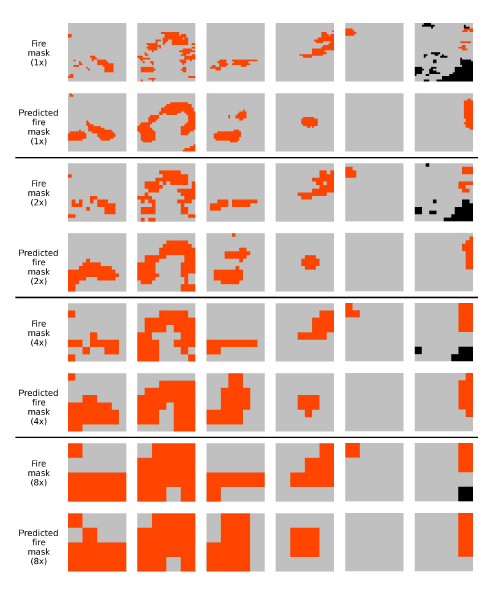

---

## <span style="color: goldenrod;">5. Machine Learning Application</span>  
The prediction task is framed as pixel-wise binary segmentation: each 64 × 64 grid with 12 channels (11 covariates + previous-day fire mask) must predict the next-day fire mask. Three model families were evaluated: 

### <span style="color: maroon;">Models & Key Formula</span>
1. **Convolutional Autoencoder**  
   A deep encoder–decoder uses 3 × 3 convolutions, residual blocks, and dropout (0.1). Training optimizes a weighted cross-entropy loss:

   $$
   L = -\frac{1}{N} \sum_{i=1}^{N} w_{c_i} \bigl[\,y_i \log p_i + (1 - y_i)\log(1 - p_i)\bigr]
   $$

   The model was trained with Adam learning rate$\ 10^{-4}\$  for 1,000 epochs on four V100 GPUs.
  

2. **Logistic Regression**  
   - Features: pixel + 8 neighbors → vector of length 9 × 12.  
   - Class weight **no-fire** = 7.
     
   This model Uses a feature vector.
   
4. **Random Forest**  
   - 100 trees, max depth = 15, **no-fire** weight = 5.  


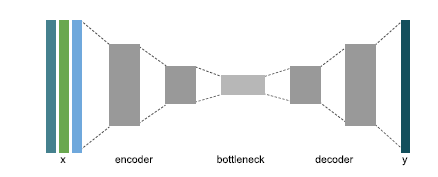

---

## <span style="color: goldenrod;">6. Results</span>   
  
### <span style="color: maroon;">Table I: Model Performance</span>
The autoencoder leads by 6–17 percentage points in AUC-PR, achieving the best balance of precision and recall.


| Model                  | AUC-PR (%) | Precision (%) | Recall (%) |
|------------------------|------------|---------------|------------|
| Persistence baseline   | 11.5       | —             | —          |
| Logistic Regression    | ~22        | 32.5          | 35.3       |
| Random Forest          | ~25        | 26.3          | 46.9       |
| **Conv. Autoencoder**  | **28.4**   | **33.6**      | **43.1**   |



### <span style="color: maroon;">Table II: Resolution Trade-Off</span> 
Coarser pixels boost AUC-PR (to ≈66%) but degrade fine-scale localization.

| Pixel Size (km) | AUC-PR (%) | Spatial Detail    |
|-----------------|------------|-------------------|
| 1 × 1           | 28.4       | High              |
| 2 × 2           | ~40        | Moderate          |
| 4 × 4           | ~55        | Low               |
| 8 × 8           | ~66        | Very Low          |


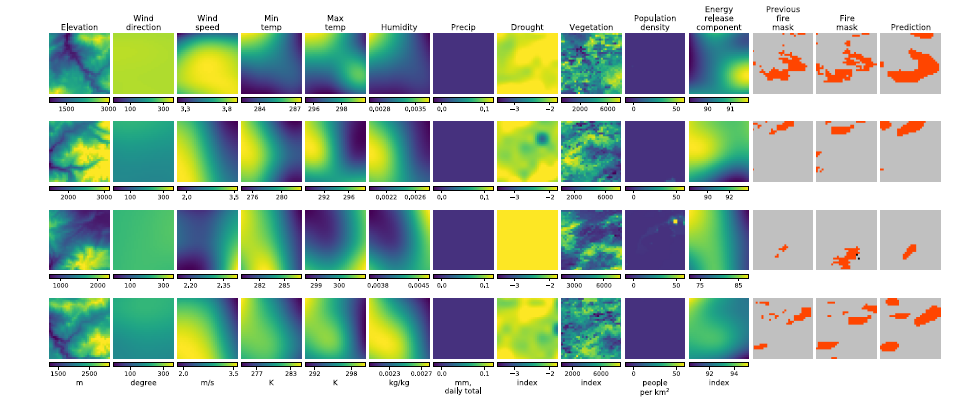

---

## <span style="color: goldenrod;">7. Feature Importance</span>  
Ablation and Random Forest’s Gini importance (Table VI) show:  
- **Top feature**: Previous day’s fire mask (removal drops AUC-PR by >5%).  
- **Secondary**: NDVI and elevation.  
- Some variables, when removed, slightly improve performance—indicating overfitting relief.  
- Minimal models with only “previous mask + NDVI” or “+ elevation” retain most accuracy.

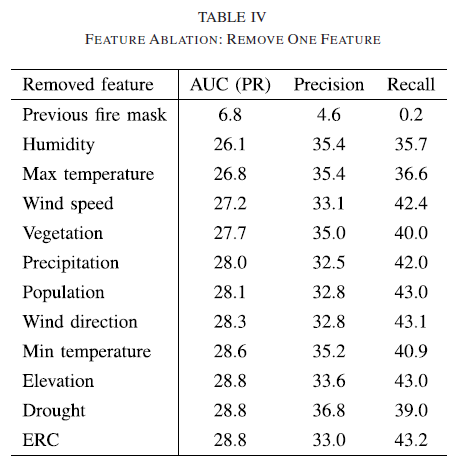

## <span style="color: goldenrod;">8. Conclusion & Future Work</span>  
**Next Day Wildfire Spread** establishes the first public benchmark for 24-hour wildfire-spread forecasting at daily, 1 km resolution. While MODIS/GRIDMET limits tactical precision and cloud cover can introduce noise, deep segmentation models demonstrate strong utility. Future extensions include:  
- Integrating higher-resolution or simulated data  
- Exploring different lead times (hourly, weekly)  
- Global dataset expansion  
- Applying the framework to other hazards (drought, storms)

---------------

### *At first, we should import the required libraries such as Numpy, Pandas, Tensorflow, Matplotlib and so on.*

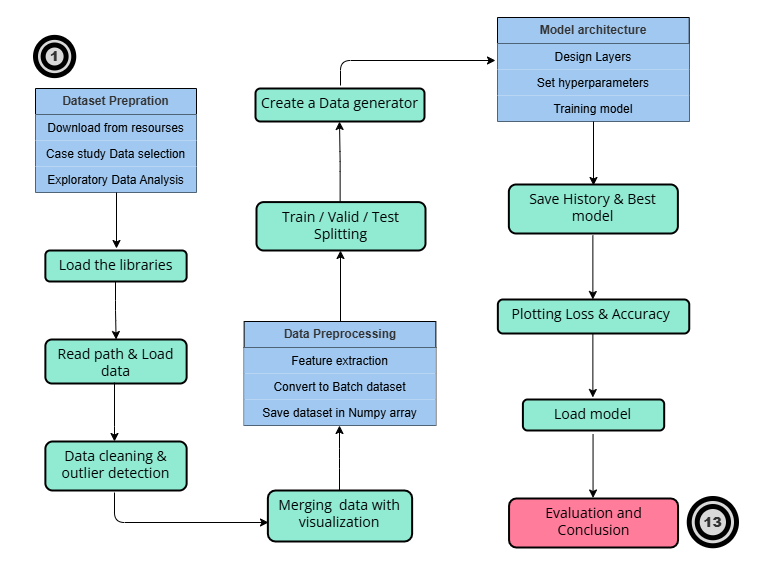

---------------

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [209]:
import tensorflow as tf
import numpy as np
import glob
import os
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import ParameterGrid
from tensorflow.keras.layers import Input, Conv2D, BatchNormalization, Dropout, Add, UpSampling2D, MaxPooling2D, concatenate
from tensorflow.keras.models import Model
import tensorflow.keras.backend as K
import gc
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.mixed_precision import set_global_policy
import shutil
from tensorflow.keras.metrics import Recall, Precision
from tensorflow.keras.utils import Sequence
from sklearn.metrics import confusion_matrix, roc_curve, auc
from prettytable import PrettyTable
import shap
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import GridSearchCV
from skimage.util import view_as_windows
import time
import psutil
import matplotlib.cm as cm
from termcolor import colored
import matplotlib.colors as mcolors
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from tensorflow.keras.utils import plot_model
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import precision_score, recall_score

## 1. Data Prepration

### *define input feature keys, parse TFRecord examples, load the dataset, and finally save processed data as NumPy arrays for efficient storage and model training.*

In [13]:
# List of input feature keys (11 + PrevFireMask)
FEATURE_KEYS = [
    'elevation', 'vs', 'th', 'tmmn', 'tmmx', 'sph',
    'pr', 'pdsi', 'NDVI', 'population', 'erc', 'PrevFireMask']

# Function to parse a single TFRecord example
def parse_example(example_proto):
    
    feature_description = {
        key: tf.io.FixedLenFeature([64*64], tf.float32) for key in FEATURE_KEYS
    }
    feature_description.update({
        'FireMask': tf.io.FixedLenFeature([64*64], tf.float32),
    })

    parsed = tf.io.parse_single_example(example_proto, feature_description)

    # Stack feature channels into a single tensor of shape (64, 64, 12)
    feature_maps = [tf.reshape(parsed[key], (64, 64, 1)) for key in FEATURE_KEYS]
    inputs = tf.concat(feature_maps, axis=-1)

    # Reshape label (FireMask) to (64, 64, 1)
    label = tf.reshape(parsed['FireMask'], (64, 64, 1))

    return inputs, label

# Function to load all TFRecords from a folder and convert to NumPy arrays
def load_dataset_from_folder(folder_path):
    
    tfrecord_paths = sorted(glob.glob(os.path.join(folder_path, "*.tfrecord")))
    assert len(tfrecord_paths) > 0, f"No TFRecord files found in {folder_path}"

    # Create a tf.data.Dataset
    dataset = tf.data.TFRecordDataset(tfrecord_paths, num_parallel_reads=tf.data.AUTOTUNE)
    dataset = dataset.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)

    # Move to GPU
    dataset = dataset.apply(tf.data.experimental.copy_to_device("/device:GPU:0"))
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    # Convert dataset to NumPy arrays
    inputs_list = []
    labels_list = []

    for inputs, label in dataset:
        inputs_list.append(inputs.numpy())
        labels_list.append(label.numpy())

    X = np.stack(inputs_list)
    y = np.stack(labels_list)

    return X, y

# Save arrays to .npy files
def save_numpy_arrays(folder_path, X, y):
    np.save(os.path.join(folder_path, "X.npy"), X)
    np.save(os.path.join(folder_path, "y.npy"), y)
    print(f"💾 Saved NumPy arrays to {folder_path}")


In [15]:
for split in ["Train", "Test", "Eval"]:
    folder = rf"D:/UNI/Arshad/Term 2/Data mining/Project/RawData/{split}"
    print(f"\n🔄 Loading {split} set...")
    X, y = load_dataset_from_folder(folder)
    print(f"✅ {split} shapes:", X.shape, y.shape)
    save_numpy_arrays(folder, X, y)


🔄 Loading Train set...
✅ Train shapes: (14979, 64, 64, 12) (14979, 64, 64, 1)
💾 Saved NumPy arrays to D:/UNI/Arshad/Term 2/Data mining/Project/RawData/Train

🔄 Loading Test set...
✅ Test shapes: (1689, 64, 64, 12) (1689, 64, 64, 1)
💾 Saved NumPy arrays to D:/UNI/Arshad/Term 2/Data mining/Project/RawData/Test

🔄 Loading Eval set...
✅ Eval shapes: (1877, 64, 64, 12) (1877, 64, 64, 1)
💾 Saved NumPy arrays to D:/UNI/Arshad/Term 2/Data mining/Project/RawData/Eval


---------------

### *Loading and Verifying Preprocessed Dataset Splits*

In [84]:
# Define the path for rading modified dataest
base_path = r"D:\UNI\Arshad\Term 2\Data mining\Project\RawData"
folders = ["train", "test", "eval"]

# Load data dynamically
for folder in folders:
    x_path = os.path.join(base_path, folder, f"X.npy")
    y_path = os.path.join(base_path, folder, f"y.npy")

    # Load the .npy files and assign to global variables
    globals()[f"input_{folder}"] = np.load(x_path)
    globals()[f"label_{folder}"] = np.load(y_path)

# Print the shapes for verification
for folder in folders:
    print(f"input_{folder}: shape {globals()[f'input_{folder}'].shape}")
    print(f"label_{folder}: shape {globals()[f'label_{folder}'].shape}")

input_train: shape (14979, 64, 64, 12)
label_train: shape (14979, 64, 64, 1)
input_test: shape (1689, 64, 64, 12)
label_test: shape (1689, 64, 64, 1)
input_eval: shape (1877, 64, 64, 12)
label_eval: shape (1877, 64, 64, 1)


---------------

### *Visualizing Sample Data Across Different Features*

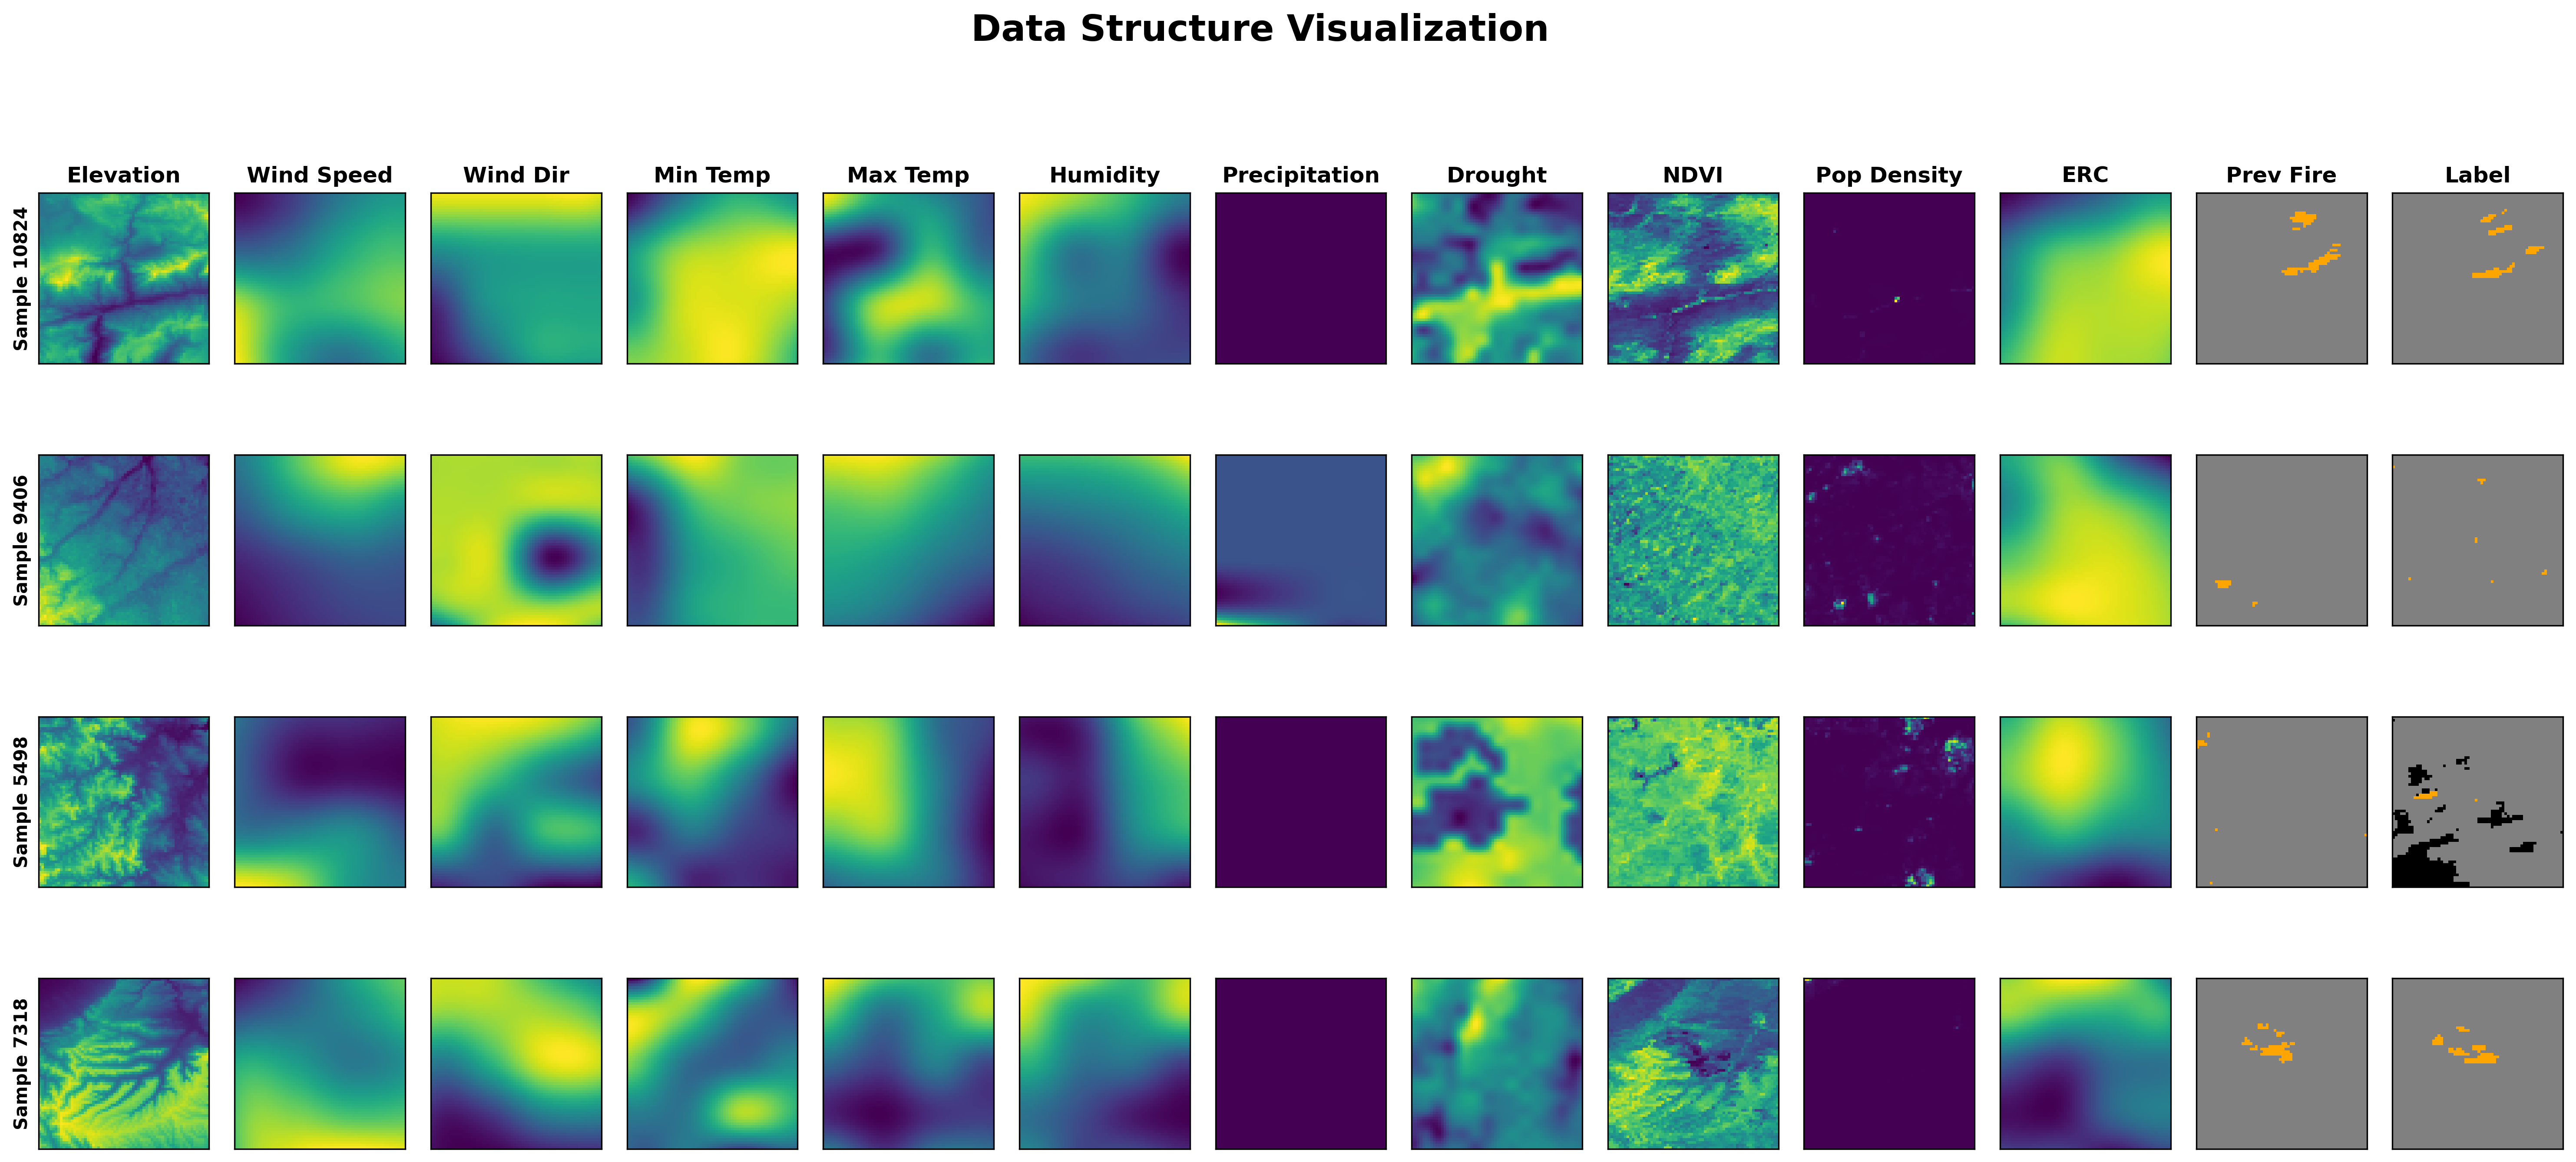

In [96]:
# Simplified feature names
name_list = [
    'Elevation', 'Wind Speed', 'Wind Dir', 'Min Temp', 'Max Temp',
    'Humidity', 'Precipitation', 'Drought', 'NDVI', 'Pop Density',
    'ERC', 'Prev Fire', 'Label']

num_samples = 4
num_features = 12

# Randomly select samples from the train set
random_indices = np.random.choice(input_train.shape[0], num_samples, replace=False)

# Define custom colormap for categorical values (-1, 0, 1)
custom_cmap = ListedColormap(["black", "gray", "orange"])

# Plot settings
fig, axes = plt.subplots(num_samples, num_features + 1, figsize=(25, 10), dpi=300)
plt.subplots_adjust(wspace=0.15)

for row_idx, sample_idx in enumerate(random_indices):
    for col_idx in range(num_features + 1):
        ax = axes[row_idx, col_idx]

        # Apply colormaps
        if col_idx < num_features - 1:  # First 11 features
            img = input_train[sample_idx, :, :, col_idx]
            ax.imshow(img, cmap='viridis')
            
        elif col_idx == num_features - 1:  # "Prev Fire"
            img = input_train[sample_idx, :, :, col_idx]
            ax.imshow(img, cmap=custom_cmap, vmin=-1, vmax=1)
            
        else:  # "Label"
            img = label_train[sample_idx, :, :, 0]
            ax.imshow(img, cmap=custom_cmap, vmin=-1, vmax=1)

        ax.set_xticks([])
        ax.set_yticks([])

        if row_idx == 0:
            ax.set_title(name_list[col_idx], fontsize=12, fontweight='bold')

        # Label sample indices
        if col_idx == 0:
            ax.set_ylabel(f"Sample {sample_idx}", fontsize=10, fontweight='bold')

plt.suptitle("Data Structure Visualization", fontsize=20, fontweight='bold', y=1.0)
plt.show()

---------------

## 2. Data Preproccesing

### *Filtering Out Invalid Samples from Dataset Splits*

In [98]:
datasets = ["train", "test", "eval"]

# Filter samples based on the last feature in input or label
for dataset in datasets:
    input_data = globals()[f"input_{dataset}"]
    label_data = globals()[f"label_{dataset}"]

    # Identify samples to remove
    invalid_samples = np.any(input_data[:, :, :, 11] == -1, axis=(1, 2)) | np.any(label_data[:, :, :, 0] == -1, axis=(1, 2))

    # Get valid indices
    valid_indices = np.where(~invalid_samples)[0]

    # Remove invalid samples
    globals()[f"input_{dataset}"] = input_data[valid_indices]
    globals()[f"label_{dataset}"] = label_data[valid_indices]

    print(f"Dataset '{dataset}': Removed {len(invalid_samples) - len(valid_indices)} samples.")

Dataset 'train': Removed 6649 samples.
Dataset 'test': Removed 822 samples.
Dataset 'eval': Removed 792 samples.


---------------

### *Applying Min-Max Normalization to Standardize Input Features*

In [100]:
# Min-Max Normalization Stats
clip_mins, clip_maxs = [], []

# Compute clipping limits using percentiles
for i in range(11):
    channel_data = input_train[:, :, :, i].flatten()
    min_val, max_val = np.percentile(channel_data, [0.5, 99.5])

    clip_mins.append(min_val)
    clip_maxs.append(max_val)

print("✅ Clipping limits computed from training set.")

# Apply Min-Max Scaling
def min_max_scale(data, clip_mins, clip_maxs):
    data = data.copy()
    
    for i in range(11):
        data[..., i] = np.clip(data[..., i], clip_mins[i], clip_maxs[i])  # Clip values
        data[..., i] = (data[..., i] - clip_mins[i]) / (clip_maxs[i] - clip_mins[i])  # Normalize to [0,1]
    return data

# Apply scaling to all datasets
input_train = min_max_scale(input_train, clip_mins, clip_maxs)
input_test = min_max_scale(input_test, clip_mins, clip_maxs)
input_eval = min_max_scale(input_eval, clip_mins, clip_maxs)

print("✅ Min-Max normalization applied to all datasets.")

✅ Clipping limits computed from training set.
✅ Min-Max normalization applied to all datasets.


---------------

### *Augmenting Training Data for Robust Model Performance*

In [12]:
# Augmentation Function for Training Data
def augment_data(input_data, label_data):
    num_samples = input_data.shape[0]
    
    # Initialize augmented arrays
    augmented_input = np.empty((num_samples, 32, 32, input_data.shape[-1]))
    augmented_label = np.empty((num_samples, 32, 32, label_data.shape[-1]))

    for i in range(num_samples):
        img = input_data[i]
        lbl = label_data[i]

        # Step 1: Random Cropping (32×32 from 64×64)
        x_start = np.random.randint(0, img.shape[0] - 32)
        y_start = np.random.randint(0, img.shape[1] - 32)
        cropped_img = img[x_start:x_start+32, y_start:y_start+32, :]
        cropped_lbl = lbl[x_start:x_start+32, y_start:y_start+32, :]

        # Step 2: Random Flip
        if np.random.rand() > 0.5:
            cropped_img = np.flipud(cropped_img)  # Vertical Flip
            cropped_lbl = np.flipud(cropped_lbl)  

        if np.random.rand() > 0.5:
            cropped_img = np.fliplr(cropped_img)  # Horizontal Flip
            cropped_lbl = np.fliplr(cropped_lbl)  

        # Step 3: Random Rotation
        rotation_degree = np.random.choice([0, 90, 180, 270])  
        cropped_img = np.rot90(cropped_img, k=rotation_degree // 90)  # Rotate accordingly
        cropped_lbl = np.rot90(cropped_lbl, k=rotation_degree // 90)  

        # Store augmented data
        augmented_input[i] = cropped_img
        augmented_label[i] = cropped_lbl

    return augmented_input, augmented_label

input_train_reconstructed, label_train_reconstructed = augment_data(input_train, label_train)

# Dimensions
INPUT_SIZE = 64
CROP_SIZE = 32
BATCH_SIZE = 32

# Convert NumPy arrays to tf.data.Dataset
train_dataset = tf.data.Dataset.from_tensor_slices((input_train, label_train))

# Shuffle before augmentation
train_dataset = train_dataset.shuffle(buffer_size=10000)

# Define augmentation function
def augment(inputs, label):
    # Concatenate input and label to apply same augmentation
    combined = tf.concat([inputs, label], axis=-1)  # shape: (64, 64, 13)

    # Random crop to 32x32
    combined = tf.image.random_crop(combined, size=[CROP_SIZE, CROP_SIZE, 13])

    # Random rotation (0, 90, 180, 270 degrees)
    k = tf.random.uniform(shape=[], minval=0, maxval=4, dtype=tf.int32)
    combined = tf.image.rot90(combined, k=k)

    # Random horizontal flip
    combined = tf.image.random_flip_left_right(combined)

    # Random vertical flip
    combined = tf.image.random_flip_up_down(combined)

    # Split input and label
    aug_input = combined[:, :, :-1]  # shape: (32, 32, 12)
    aug_label = combined[:, :, -1:]  # shape: (32, 32, 1)

    return aug_input, aug_label

# Apply augmentation
train_dataset = train_dataset.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Convert train_dataset back to NumPy arrays
input_train_list = []
label_train_list = []

for input_batch, label_batch in train_dataset:
    input_train_list.append(input_batch.numpy())  # Convert to NumPy
    label_train_list.append(label_batch.numpy())  # Convert to NumPy

# Concatenate all batches into full dataset
input_train_aug = np.concatenate(input_train_list, axis=0)
label_train_aug = np.concatenate(label_train_list, axis=0)

print("✅ Augmentation applied successfully to the training dataset.")

✅ Augmentation applied successfully to the training dataset.


---------------

In [27]:
# Define the base path for clean data
base_path = r"D:\UNI\Arshad\Term 2\Data mining\Project\RawData"

# Dictionary containing data and corresponding folders
data_dict = {
    "train": {"input": input_train, "label": label_train},
    "test": {"input": input_test, "label": label_test},
    "eval": {"input": input_eval, "label": label_eval},
}

# save the arrays
for folder, data in data_dict.items():
    folder_path = os.path.join(base_path, folder)
    os.makedirs(folder_path, exist_ok=True)
    
    np.save(os.path.join(folder_path, "input.npy"), data["input"])
    np.save(os.path.join(folder_path, "label.npy"), data["label"])

print("✅ Clean dataset successfully saved.")

✅ Clean dataset successfully saved.


---------------

### *Splitting and Structuring Processed Data for Model Training*

In [29]:
def split_and_process_data(raw_data_path, output_path):
    """
    Process raw NPY files into individual samples with proper directory structure
    """
    print("🔹 Starting Data Processing Phase")
    print("="*40)
    
    # Create output directory structure
    splits = ['train', 'test', 'eval']
    for split in splits:
        split_dir = os.path.join(output_path, 'data', split)
        os.makedirs(os.path.join(split_dir, 'inputs'), exist_ok=True)
        os.makedirs(os.path.join(split_dir, 'labels'), exist_ok=True)

    # Process each dataset split
    for split in splits:
        print(f"\nProcessing {split} data...")
        
        # Load raw data
        input_path = os.path.join(raw_data_path, split, 'input.npy')
        label_path = os.path.join(raw_data_path, split, 'label.npy')
        
        if not os.path.exists(input_path):
            raise FileNotFoundError(f"Input file not found: {input_path}")
        if not os.path.exists(label_path):
            raise FileNotFoundError(f"Label file not found: {label_path}")
            
        inputs = np.load(input_path)
        labels = np.load(label_path)
        
        # Validate data
        assert inputs.shape[0] == labels.shape[0], \
            f"Mismatch in samples: {inputs.shape[0]} inputs vs {labels.shape[0]} labels"
        
        # Save individual samples
        num_samples = inputs.shape[0]
        for i in range(num_samples):
            input_file = os.path.join(output_path, 'data', split, 'inputs', f'i_{i:05d}.npy')
            np.save(input_file, inputs[i])
            
            # Save label
            label_file = os.path.join(output_path, 'data', split, 'labels', f'l_{i:05d}.npy')
            np.save(label_file, labels[i])
        
        print(f"Saved {num_samples} {split} samples")

    print("\n✅ Data processing completed successfully!")

RAW_DATA_ROOT = r"D:/UNI/Arshad/Term 2/Data mining/Project/RawData"
PROCESSED_DATA_ROOT = r"D:/UNI/Arshad/Term 2/Data mining/Project"
    
split_and_process_data(raw_data_path=RAW_DATA_ROOT, output_path=PROCESSED_DATA_ROOT)

🔹 Starting Data Processing Phase

Processing train data...
Saved 8330 train samples

Processing test data...
Saved 867 test samples

Processing eval data...
Saved 1085 eval samples

✅ Data processing completed successfully!


---------------

### *Building a Data Generator for Efficient Batch Processing*

In [6]:
RAW_DATA_ROOT = r"D:/UNI/Arshad/Term 2/Data mining/Project/RawData"
PROCESSED_DATA_ROOT = r"D:/UNI/Arshad/Term 2/Data mining/Project"

class DataGenerator(Sequence):
    """Generates batches of data from processed numpy files"""
    
    def __init__(self, input_dir, label_dir, batch_size=32, shuffle=True):
        self.input_dir = input_dir
        self.label_dir = label_dir
        self.batch_size = batch_size
        self.shuffle = shuffle
        
        # Get sorted file lists
        self.input_files = sorted(
            [f for f in os.listdir(input_dir) if f.startswith('i_')],
            key=lambda x: int(x.split('_')[1].split('.')[0]))
        
        self.label_files = sorted(
            [f for f in os.listdir(label_dir) if f.startswith('l_')],
            key=lambda x: int(x.split('_')[1].split('.')[0]))
        
        # Validate dataset
        assert len(self.input_files) == len(self.label_files), \
            "Input/Label file count mismatch"
        
        self.num_samples = len(self.input_files)
        self.indices = np.arange(self.num_samples)
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(self.num_samples / self.batch_size))

    def __getitem__(self, index):
        batch_indices = self.indices[index*self.batch_size : (index+1)*self.batch_size]
        
        X = []
        y = []
        
        for i in batch_indices:
            X.append(np.load(os.path.join(self.input_dir, self.input_files[i])))
            y.append(np.load(os.path.join(self.label_dir, self.label_files[i])))
            
        return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

# Create generators
base_path = os.path.join(PROCESSED_DATA_ROOT, 'data')
    
train_gen = DataGenerator(
        input_dir=os.path.join(base_path, 'train', 'inputs'),
        label_dir=os.path.join(base_path, 'train', 'labels'),
        batch_size=32,
        shuffle=True)
    
test_gen = DataGenerator(
        input_dir=os.path.join(base_path, 'test', 'inputs'),
        label_dir=os.path.join(base_path, 'test', 'labels'),
        batch_size=32,
        shuffle=False)
    
eval_gen = DataGenerator(
        input_dir=os.path.join(base_path, 'eval', 'inputs'),
        label_dir=os.path.join(base_path, 'eval', 'labels'),
        batch_size=32,
        shuffle=False)
    
# Verify generators
print("\nGenerator Verification:")
print(f"Train batches: {len(train_gen)}")
print(f"Test batches: {len(test_gen)}")
print(f"Eval batches: {len(eval_gen)}")
    
sample_X, sample_y = train_gen[0]
print("\nSample Batch Details:")
print(f"Input shape: {sample_X.shape}")
print(f"Label shape: {sample_y.shape}")
print(f"Input dtype: {sample_X.dtype}")
print(f"Label dtype: {sample_y.dtype}")
    
print("\n✅ Data pipeline ready for training!")


Generator Verification:
Train batches: 261
Test batches: 28
Eval batches: 34

Sample Batch Details:
Input shape: (32, 64, 64, 12)
Label shape: (32, 64, 64, 1)
Input dtype: float32
Label dtype: float32

✅ Data pipeline ready for training!


---------------

In [33]:
gc.collect()

21

---------------

## 3. Model

### *Model 1 : Residual-Based CNN Model*

This deep learning model uses **residual blocks** to improve gradient flow and feature extraction. It consists of **four stacked residual blocks**, followed by convolutional layers with batch normalization for refinement. A **sigmoid activation** produces probability-based outputs. The model employs a **weighted cross-entropy loss** to prioritize positive samples, enhancing fire prediction accuracy. 🚀


In [12]:
def residual_block(x, filters):
    """Creates a residual block with two convolutional layers and skip connection"""
    res = Conv2D(filters, (3, 3), padding='same', activation='relu')(x)
    res = BatchNormalization()(res)
    res = Conv2D(filters, (3, 3), padding='same')(res)
    res = BatchNormalization()(res)
    res = Add()([x, res])  # Skip connection
    res = Dropout(0.3)(res)
    return res

# Define Model
def create_model(input_shape=(64, 64, 12)):
    inputs = Input(shape=input_shape)
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
    x = BatchNormalization()(x)
    
    # Stack residual blocks
    for _ in range(4):
        x = residual_block(x, 64)
    
    # UpSampling layers
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Conv2D(16, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Conv2D(8, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    
    outputs = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)
    return Model(inputs, outputs)
    
# Custom Loss
def weighted_cross_entropy(y_true, y_pred):
    weights = tf.where(y_true == 1, 2.5, 1.0)
    loss = K.binary_crossentropy(y_true, y_pred)
    return K.mean(loss * weights)

model = create_model()
model.summary()

Model: "model_2"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_3 (InputLayer)           [(None, 64, 64, 12)  0           []                               
                                ]                                                                 
                                                                                                  
 conv2d_26 (Conv2D)             (None, 64, 64, 64)   6976        ['input_3[0][0]']                
                                                                                                  
 batch_normalization_24 (BatchN  (None, 64, 64, 64)  256         ['conv2d_26[0][0]']              
 ormalization)                                                                                    
                                                                                            

### *Automated Hyperparameter Optimization Using Grid Search*

In [17]:
# Hyperparameter configuration
param_grid = {
    'learning_rate': [0.0001, 0.001],
    'optimizer': ['adam', 'rmsprop', 'sgd'],
    'batch_size': [32, 64],
    'dropout_rate': [0.2, 0.3]}

# Path configuration
BASE_DATA_PATH = r"D:/UNI/Arshad/Term 2/Data mining/Project/data"
best_params = None
best_loss = float('inf')

# Grid search execution
for params in ParameterGrid(param_grid):
    print(f"\n🔹 Testing Hyperparameters: {params}")
    print('-------------------------------------------------------------------------------------------------------------------------------------')
        
    # Clear previous models from memory
    tf.keras.backend.clear_session()

    # Initialize data generators
    train_gen = DataGenerator(
        input_dir=os.path.join(BASE_DATA_PATH, 'train', 'inputs'),
        label_dir=os.path.join(BASE_DATA_PATH, 'train', 'labels'),
        batch_size=params['batch_size'],
        shuffle=True)

    eval_gen = DataGenerator(
        input_dir=os.path.join(BASE_DATA_PATH, 'eval', 'inputs'),
        label_dir=os.path.join(BASE_DATA_PATH, 'eval', 'labels'),
        batch_size=params['batch_size'],
        shuffle=False)

    # Create fresh model instance
    model = create_model()

    # Configure optimizer
    if params['optimizer'] == 'adam':
        optimizer = tf.keras.optimizers.Adam(learning_rate=params['learning_rate'])
    elif params['optimizer'] == 'rmsprop':
        optimizer = tf.keras.optimizers.RMSprop(learning_rate=params['learning_rate'])
    else:
        optimizer = tf.keras.optimizers.SGD(learning_rate=params['learning_rate'])

    # Compile model
    model.compile(
        optimizer=optimizer,
        loss=weighted_cross_entropy,
        metrics=['accuracy', Recall(name='recall'), Precision(name='precision')])

    # Configure callbacks
    checkpoint = ModelCheckpoint(
        'best_model.h5',
        monitor='val_loss',
        save_best_only=True,
        verbose=0)
        
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True)

    # Train model
    history = model.fit(
        train_gen,
        epochs=5,
        steps_per_epoch=len(train_gen),
        validation_data=eval_gen,
        validation_steps=len(eval_gen),
        callbacks=[checkpoint, early_stop],
        verbose=1)

    # Track best parameters
    current_val_loss = min(history.history['val_loss'])
    if current_val_loss < best_loss:
        best_loss = current_val_loss
        best_params = params

# Final results
print('-----------------------------------------------------------------')
print("\n✅ Best Hyperparameters:")
print(f"Learning Rate: {best_params['learning_rate']}")
print(f"Batch Size: {best_params['batch_size']}")
print(f"Optimizer: {best_params['optimizer']}")
print(f"Dropout Rate: {best_params['dropout_rate']}")
print(f"Best Validation Loss: {best_loss:.4f}")


🔹 Testing Hyperparameters: {'batch_size': 32, 'dropout_rate': 0.2, 'learning_rate': 0.0001, 'optimizer': 'adam'}
-------------------------------------------------------------------------------------------------------------------------------------
Epoch 1/5
261/261 [==============================] - 33s 123ms/step - loss: 0.6425 - accuracy: 0.7034 - recall: 0.6732 - precision: 0.0276 - val_loss: 0.4510 - val_accuracy: 0.9770 - val_recall: 0.2286 - val_precision: 0.2588
Epoch 2/5
261/261 [==============================] - 31s 119ms/step - loss: 0.4638 - accuracy: 0.9547 - recall: 0.6216 - precision: 0.1586 - val_loss: 0.3775 - val_accuracy: 0.9691 - val_recall: 0.3891 - val_precision: 0.2300
Epoch 3/5
261/261 [==============================] - 31s 120ms/step - loss: 0.3572 - accuracy: 0.9743 - recall: 0.5656 - precision: 0.2549 - val_loss: 0.3172 - val_accuracy: 0.9720 - val_recall: 0.3655 - val_precision: 0.2487
Epoch 4/5
261/261 [==============================] - 31s 120ms/step - loss

---------------

### *Final Model Training & Evaluation*

In [20]:
# Define residual block with skip connection and dropout
def residual_block(x, filters, dropout_rate):
    """Creates a residual block with two convolutional layers, batch normalization, skip connection, and dropout."""
    res = Conv2D(filters, (3, 3), padding='same', activation='relu')(x)
    res = BatchNormalization()(res)
    res = Conv2D(filters, (3, 3), padding='same')(res)
    res = BatchNormalization()(res)
    res = Add()([x, res])  # Skip connection
    res = Dropout(dropout_rate)(res)  # Apply dropout
    return res

# Define model architecture
def create_model(input_shape=(64, 64, 12), dropout_rate=0.2):
    """Creates a convolutional model with residual blocks and dropout."""
    inputs = Input(shape=input_shape)
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
    x = BatchNormalization()(x)
    
    # Stack residual blocks
    for _ in range(4):
        x = residual_block(x, 64, dropout_rate)
    
    # UpSampling layers
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Conv2D(16, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Conv2D(8, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    
    outputs = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)
    return Model(inputs, outputs)

# Initialize final model with best parameters
final_model = create_model(
    input_shape=(64, 64, 12),
    dropout_rate=best_params['dropout_rate'])

# Configure final optimizer
if best_params['optimizer'] == 'adam':
    final_optimizer = tf.keras.optimizers.Adam(learning_rate=best_params['learning_rate'])
elif best_params['optimizer'] == 'rmsprop':
    final_optimizer = tf.keras.optimizers.RMSprop(learning_rate=best_params['learning_rate'])
else:
    final_optimizer = tf.keras.optimizers.SGD(learning_rate=best_params['learning_rate'])

# Compile final model
final_model.compile(
    optimizer=final_optimizer,
    loss=weighted_cross_entropy,
    metrics=[
        'accuracy',
        Recall(name='recall'),
        Precision(name='precision')])

final_model.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_2 (InputLayer)           [(None, 64, 64, 12)  0           []                               
                                ]                                                                 
                                                                                                  
 conv2d_13 (Conv2D)             (None, 64, 64, 64)   6976        ['input_2[0][0]']                
                                                                                                  
 batch_normalization_12 (BatchN  (None, 64, 64, 64)  256         ['conv2d_13[0][0]']              
 ormalization)                                                                                    
                                                                                            

In [56]:
# Initialize data generators
final_train_gen = DataGenerator(
    input_dir=os.path.join(BASE_DATA_PATH, 'train', 'inputs'),
    label_dir=os.path.join(BASE_DATA_PATH, 'train', 'labels'),
    batch_size=best_params['batch_size'],
    shuffle=True)

final_eval_gen = DataGenerator(
    input_dir=os.path.join(BASE_DATA_PATH, 'eval', 'inputs'),
    label_dir=os.path.join(BASE_DATA_PATH, 'eval', 'labels'),
    batch_size=best_params['batch_size'],
    shuffle=False)

# Train final model
final_history = final_model.fit(
    final_train_gen,
    epochs=50,
    steps_per_epoch=len(final_train_gen),
    validation_data=final_eval_gen,
    validation_steps=len(final_eval_gen),
    callbacks=[EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True),
    ModelCheckpoint(os.path.join(r"D:\UNI\Arshad\Term 2\Data mining\Project\Model", 'final_model.h5'), 
                    save_best_only=True, 
                    monitor='val_loss')],
    verbose=1)

Epoch 1/50
261/261 [==============================] - 32s 121ms/step - loss: 0.0663 - accuracy: 0.9858 - recall: 0.4342 - precision: 0.4253 - val_loss: 0.1467 - val_accuracy: 0.9811 - val_recall: 0.1792 - val_precision: 0.3399
Epoch 2/50
261/261 [==============================] - 32s 121ms/step - loss: 0.0655 - accuracy: 0.9859 - recall: 0.4430 - precision: 0.4311 - val_loss: 0.1256 - val_accuracy: 0.9787 - val_recall: 0.2483 - val_precision: 0.3033
Epoch 3/50
261/261 [==============================] - 31s 120ms/step - loss: 0.0644 - accuracy: 0.9860 - recall: 0.4580 - precision: 0.4366 - val_loss: 0.1295 - val_accuracy: 0.9797 - val_recall: 0.2263 - val_precision: 0.3175
Epoch 4/50
261/261 [==============================] - 31s 119ms/step - loss: 0.0638 - accuracy: 0.9861 - recall: 0.4644 - precision: 0.4408 - val_loss: 0.1238 - val_accuracy: 0.9787 - val_recall: 0.2148 - val_precision: 0.2873
Epoch 5/50
261/261 [==============================] - 31s 119ms/step - loss: 0.0633 - accura

---------------

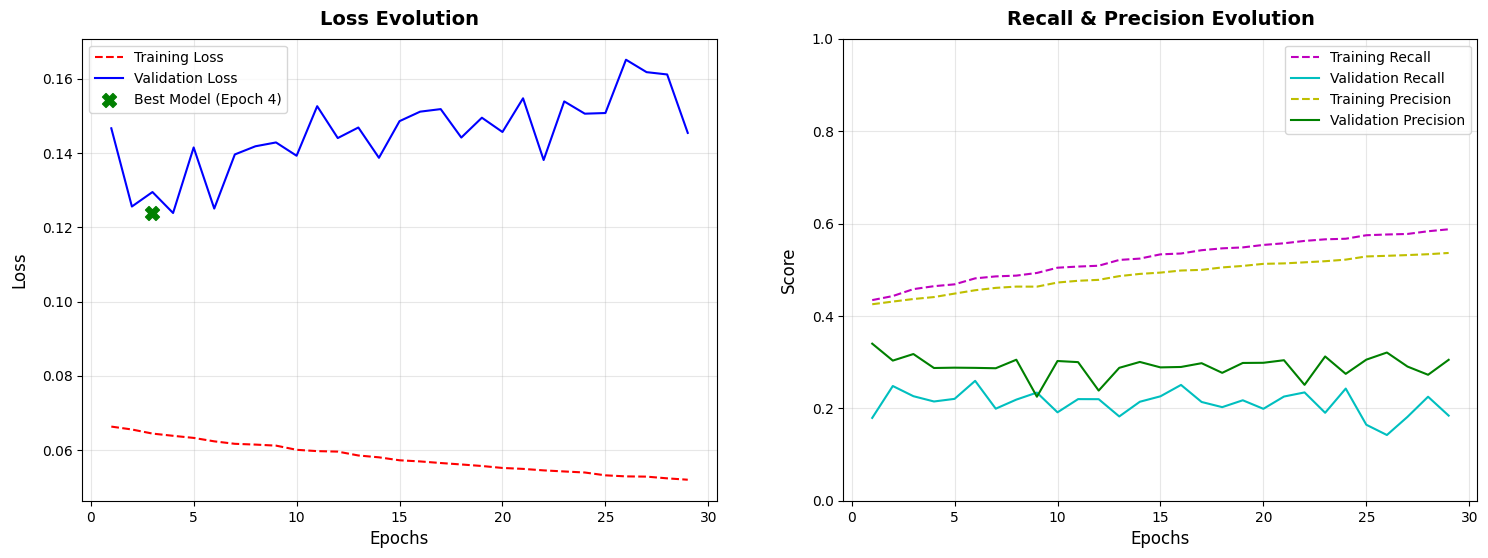

In [57]:
# Create training curves visualization
def plot_training_history(final_history):
    """Generates customized training performance plots"""
    fig, ax = plt.subplots(1, 2, figsize=(18, 6))
    plt.subplots_adjust(hspace=0.1)
    
    # Loss plot
    loss = final_history.history['loss']
    val_loss = final_history.history['val_loss']
    epochs = range(1, len(loss)+1)
    
    ax[0].plot(epochs, loss, 'r--', label='Training Loss')
    ax[0].plot(epochs, val_loss, 'b-', label='Validation Loss')
    ax[0].scatter(np.argmin(val_loss), np.min(val_loss), s=100, marker='X', color='g', 
                label=f'Best Model (Epoch {np.argmin(val_loss)+1})')
    ax[0].set_title('Loss Evolution', fontsize=14, pad=10, fontweight='bold')
    ax[0].set_xlabel('Epochs', fontsize=12)
    ax[0].set_ylabel('Loss', fontsize=12, labelpad=10)
    ax[0].grid(alpha=0.3)
    ax[0].legend()
    
    # Metrics plot
    recall = final_history.history['recall']
    val_recall = final_history.history['val_recall']
    precision = final_history.history['precision']
    val_precision = final_history.history['val_precision']
    
    ax[1].plot(epochs, recall, 'm--', label='Training Recall')
    ax[1].plot(epochs, val_recall, 'c-', label='Validation Recall')
    ax[1].plot(epochs, precision, 'y--', label='Training Precision')
    ax[1].plot(epochs, val_precision, 'g-', label='Validation Precision')
    ax[1].set_title('Recall & Precision Evolution', fontsize=14, pad=10, fontweight='bold')
    ax[1].set_xlabel('Epochs', fontsize=12)
    ax[1].set_ylabel('Score', fontsize=12, labelpad=10)
    ax[1].set_ylim([0, 1])
    ax[1].grid(alpha=0.3)
    ax[1].legend()
    
    plt.show()

# Generate plots
plot_training_history(final_history)

---------------

In [58]:
BASE_DATA_PATH = r"D:/UNI/Arshad/Term 2/Data mining/Project/data"

# Final model evaluation
test_gen = DataGenerator(
    input_dir=os.path.join(BASE_DATA_PATH, 'test', 'inputs'),
    label_dir=os.path.join(BASE_DATA_PATH, 'test', 'labels'),
    batch_size=best_params['batch_size'],
    shuffle=False)

final_model = tf.keras.models.load_model(
    os.path.join(r"D:\UNI\Arshad\Term 2\Data mining\Project\Model", 'final_model.h5'),
    custom_objects={
        'weighted_cross_entropy': weighted_cross_entropy,
        'recall': Recall(),
        'precision': Precision()})

test_results = final_model.evaluate(test_gen)
print("\n🔥 Final Test Performance:")
print(f"Loss: {test_results[0]:.4f}")
print(f"Accuracy: {test_results[1]:.4f}")
print(f"Recall: {test_results[2]:.4f}")
print(f"Precision: {test_results[3]:.4f}")

28/28 [==============================] - 1s 30ms/step - loss: 0.0836 - accuracy: 0.9843 - recall: 0.3619 - precision: 0.3584

🔥 Final Test Performance:
Loss: 0.0836
Accuracy: 0.9843
Recall: 0.3619
Precision: 0.3584


---------------

### *Model 2 : U-Net Architecture for Segmentation-Based Prediction*

- This model is based on the **U-Net architecture**, designed for segmentation tasks. It features an **encoder-decoder structure** where convolutional layers extract spatial features, followed by downsampling via **max pooling**. The bottleneck enhances feature representation before the decoder reconstructs spatial details using **upsampling and skip connections** to retain information from earlier layers. 

- Batch normalization and dropout layers improve stability and generalization, while the final **sigmoid activation** produces pixel-wise probabilities. The model is trained with a **weighted cross-entropy loss**, using an adaptive **optimizer** to refine learning. 🚀


In [66]:
BASE_DATA_PATH = r"D:/UNI/Arshad/Term 2/Data mining/Project/data"
MODEL_SAVE_PATH = r"D:/UNI/Arshad/Term 2/Data mining/Project/Model/unet_model.h5"

best_params = {
    'learning_rate': 0.001,
    'optimizer': 'adam',
    'batch_size': 32,
    'dropout_rate': 0.3}

# Define U-Net model architecture
def build_unet_model(input_shape=(64, 64, 12), dropout_rate=0.3):
    inputs = Input(shape=input_shape)

    # Encoder
    c1 = Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
    c1 = BatchNormalization()(c1)
    c1 = Dropout(dropout_rate)(c1)
    c1 = Conv2D(64, (3, 3), activation='relu', padding='same')(c1)
    p1 = MaxPooling2D((2, 2))(c1)

    c2 = Conv2D(128, (3, 3), activation='relu', padding='same')(p1)
    c2 = BatchNormalization()(c2)
    c2 = Dropout(dropout_rate)(c2)
    c2 = Conv2D(128, (3, 3), activation='relu', padding='same')(c2)
    p2 = MaxPooling2D((2, 2))(c2)

    c3 = Conv2D(256, (3, 3), activation='relu', padding='same')(p2)
    c3 = BatchNormalization()(c3)
    c3 = Dropout(dropout_rate)(c3)
    c3 = Conv2D(256, (3, 3), activation='relu', padding='same')(c3)
    p3 = MaxPooling2D((2, 2))(c3)

    # Bottleneck
    c4 = Conv2D(512, (3, 3), activation='relu', padding='same')(p3)
    c4 = BatchNormalization()(c4)
    c4 = Dropout(dropout_rate)(c4)
    c4 = Conv2D(512, (3, 3), activation='relu', padding='same')(c4)

    # Decoder
    u5 = UpSampling2D((2, 2))(c4)
    u5 = concatenate([u5, c3])
    c5 = Conv2D(256, (3, 3), activation='relu', padding='same')(u5)
    c5 = BatchNormalization()(c5)
    c5 = Dropout(dropout_rate)(c5)
    c5 = Conv2D(256, (3, 3), activation='relu', padding='same')(c5)

    u6 = UpSampling2D((2, 2))(c5)
    u6 = concatenate([u6, c2])
    c6 = Conv2D(128, (3, 3), activation='relu', padding='same')(u6)
    c6 = BatchNormalization()(c6)
    c6 = Dropout(dropout_rate)(c6)
    c6 = Conv2D(128, (3, 3), activation='relu', padding='same')(c6)

    u7 = UpSampling2D((2, 2))(c6)
    u7 = concatenate([u7, c1])
    c7 = Conv2D(64, (3, 3), activation='relu', padding='same')(u7)
    c7 = BatchNormalization()(c7)
    c7 = Dropout(dropout_rate)(c7)
    c7 = Conv2D(64, (3, 3), activation='relu', padding='same')(c7)

    outputs = Conv2D(1, (1, 1), activation='sigmoid')(c7)

    model = Model(inputs, outputs)
    return model

# Build and compile model
unet_model = build_unet_model(dropout_rate=best_params['dropout_rate'])

if best_params['optimizer'] == 'adam':
    optimizer = tf.keras.optimizers.Adam(learning_rate=best_params['learning_rate'])
elif best_params['optimizer'] == 'rmsprop':
    optimizer = tf.keras.optimizers.RMSprop(learning_rate=best_params['learning_rate'])
else:
    optimizer = tf.keras.optimizers.SGD(learning_rate=best_params['learning_rate'])

unet_model.compile(
    optimizer=optimizer,
    loss=weighted_cross_entropy,
    metrics=['accuracy', Recall(name='recall'), Precision(name='precision')]
)

unet_model.summary()

Model: "model_2"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_5 (InputLayer)           [(None, 64, 64, 12)  0           []                               
                                ]                                                                 
                                                                                                  
 conv2d_36 (Conv2D)             (None, 64, 64, 64)   6976        ['input_5[0][0]']                
                                                                                                  
 batch_normalization_29 (BatchN  (None, 64, 64, 64)  256         ['conv2d_36[0][0]']              
 ormalization)                                                                                    
                                                                                            

In [68]:
train_gen = DataGenerator(
    input_dir=os.path.join(BASE_DATA_PATH, 'train', 'inputs'),
    label_dir=os.path.join(BASE_DATA_PATH, 'train', 'labels'),
    batch_size=best_params['batch_size'],
    shuffle=True)

eval_gen = DataGenerator(
    input_dir=os.path.join(BASE_DATA_PATH, 'eval', 'inputs'),
    label_dir=os.path.join(BASE_DATA_PATH, 'eval', 'labels'),
    batch_size=best_params['batch_size'],
    shuffle=False)

unet_history = unet_model.fit(
    train_gen,
    validation_data=eval_gen,
    epochs=50,
    steps_per_epoch=len(train_gen),
    validation_steps=len(eval_gen),
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True),
        ModelCheckpoint(MODEL_SAVE_PATH, monitor='val_loss', save_best_only=True)],
    verbose=1)

Epoch 1/50
261/261 [==============================] - 38s 125ms/step - loss: 0.0862 - accuracy: 0.9823 - recall: 0.2789 - precision: 0.2794 - val_loss: 0.1517 - val_accuracy: 0.9836 - val_recall: 0.0330 - val_precision: 0.4030
Epoch 2/50
261/261 [==============================] - 30s 113ms/step - loss: 0.0692 - accuracy: 0.9850 - recall: 0.3607 - precision: 0.3827 - val_loss: 0.1186 - val_accuracy: 0.9754 - val_recall: 0.3818 - val_precision: 0.2970
Epoch 3/50
261/261 [==============================] - 30s 113ms/step - loss: 0.0663 - accuracy: 0.9851 - recall: 0.4034 - precision: 0.3953 - val_loss: 0.1159 - val_accuracy: 0.9813 - val_recall: 0.2521 - val_precision: 0.3803
Epoch 4/50
261/261 [==============================] - 29s 112ms/step - loss: 0.0642 - accuracy: 0.9854 - recall: 0.4306 - precision: 0.4108 - val_loss: 0.1174 - val_accuracy: 0.9803 - val_recall: 0.2967 - val_precision: 0.3649
Epoch 5/50
261/261 [==============================] - 29s 112ms/step - loss: 0.0631 - accura

---------------

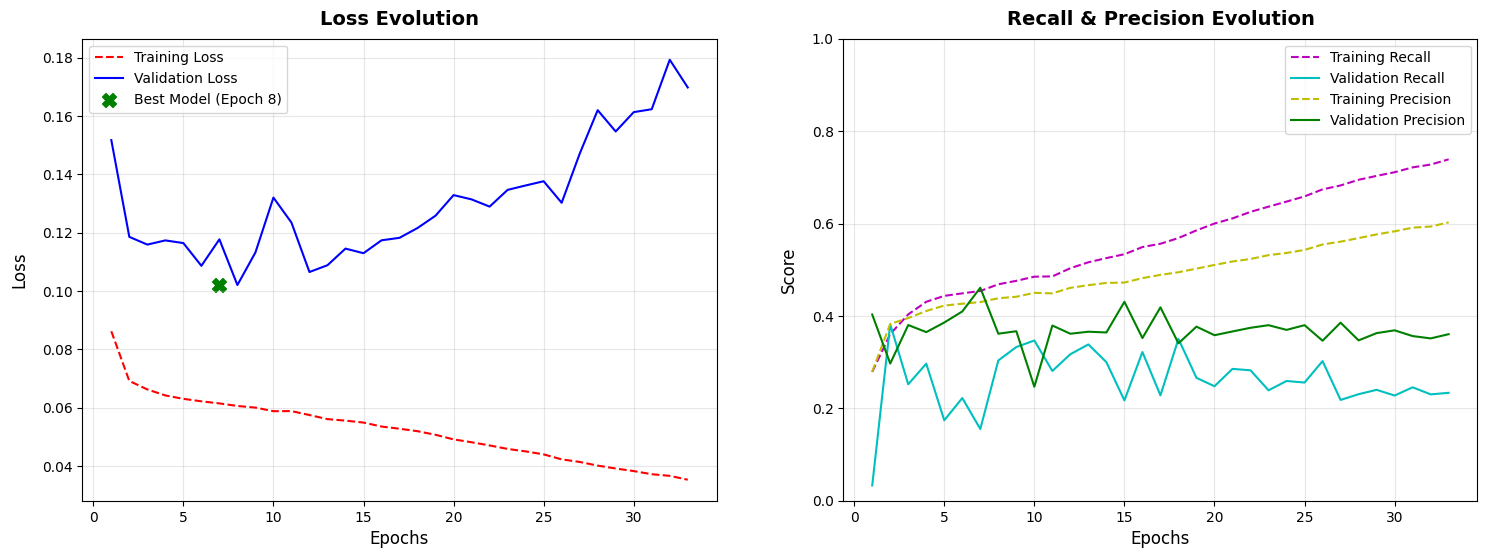

In [70]:
plot_training_history(unet_history)

---------------

In [72]:
unet_final_model = tf.keras.models.load_model(
    MODEL_SAVE_PATH,
    custom_objects={
        'weighted_cross_entropy': weighted_cross_entropy,
        'recall': Recall(),
        'precision': Precision()})

results = unet_final_model.evaluate(test_gen)
print("\n🔥 Final Test Evaluation:")
print(f"Loss: {results[0]:.4f}")
print(f"Accuracy: {results[1]:.4f}")
print(f"Recall: {results[2]:.4f}")
print(f"Precision: {results[3]:.4f}")

28/28 [==============================] - 2s 58ms/step - loss: 0.0708 - accuracy: 0.9855 - recall: 0.4309 - precision: 0.4106

🔥 Final Test Evaluation:
Loss: 0.0708
Accuracy: 0.9855
Recall: 0.4309
Precision: 0.4106


---------------

## 4.Evaluation & Visualization

### *Comparing Model Performance Using Confusion Matrices*

28/28 [==============================] - 1s 28ms/step


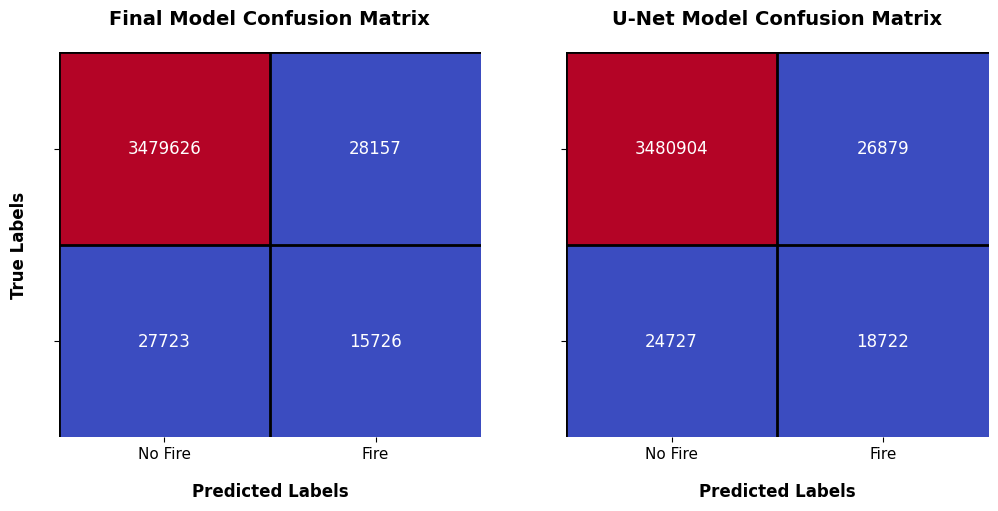

In [78]:
# Generate predictions and probabilities for both models
y_true = np.concatenate([y for _, y in test_gen])

y_pred_final = final_model.predict(test_gen).flatten()
y_pred_binary_final = (y_pred_final > 0.5).astype(int)

y_pred_unet = unet_final_model.predict(test_gen).flatten()
y_pred_binary_unet = (y_pred_unet > 0.5).astype(int)

# Calculate confusion matrices
cm_final = confusion_matrix(y_true.flatten(), y_pred_binary_final)
cm_unet = confusion_matrix(y_true.flatten(), y_pred_binary_unet)

# Plot both confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Define function to draw grid lines
def draw_grid(ax):
    for i in range(2):
        ax.axhline(i, color='black', linewidth=2)
        ax.axvline(i, color='black', linewidth=2)

# Final model confusion matrix
ax1 = sns.heatmap(cm_final, annot=True, fmt="d", cmap="coolwarm", 
                   cbar=False, annot_kws={"size":12},
                   xticklabels=["No Fire", "Fire"], 
                   yticklabels=["No Fire", "Fire"], ax=axes[0])

ax1.set_title("Final Model Confusion Matrix", fontsize=14, pad=20, weight="bold")
ax1.set_xlabel("Predicted Labels", fontsize=12, labelpad=15, weight="bold")
ax1.set_ylabel("True Labels", fontsize=12, labelpad=15, weight="bold")
ax1.xaxis.set_ticklabels(["No Fire", "Fire"], rotation=0, fontsize=11)
ax1.yaxis.set_ticklabels(["No Fire", "Fire"], rotation=0, fontsize=11)

draw_grid(ax1)

# U-Net model confusion matrix (without Y label)
ax2 = sns.heatmap(cm_unet, annot=True, fmt="d", cmap="coolwarm", 
                   cbar=False, annot_kws={"size":12},
                   xticklabels=["No Fire", "Fire"], 
                   yticklabels=["", ""], ax=axes[1])

ax2.set_title("U-Net Model Confusion Matrix", fontsize=14, pad=20, weight="bold")
ax2.set_xlabel("Predicted Labels", fontsize=12, labelpad=15, weight="bold")
ax2.xaxis.set_ticklabels(["No Fire", "Fire"], rotation=0, fontsize=11)

draw_grid(ax2)

plt.show()

---------------

### *Comparing Model Performance Using ROC Curves*


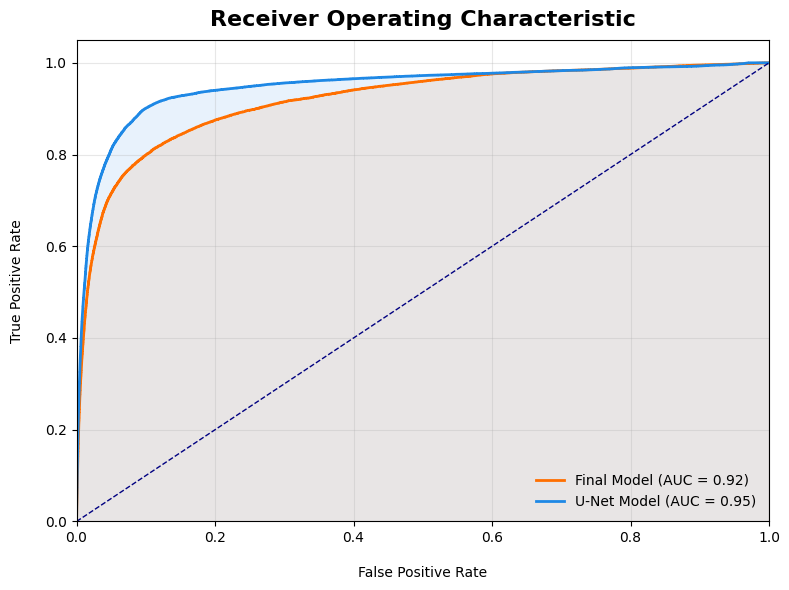

In [80]:
# Calculate ROC curve for both models
fpr_final, tpr_final, _ = roc_curve(y_true.flatten(), y_pred_final)
roc_auc_final = auc(fpr_final, tpr_final)

fpr_unet, tpr_unet, _ = roc_curve(y_true.flatten(), y_pred_unet)
roc_auc_unet = auc(fpr_unet, tpr_unet)

# Enhanced ROC Curve Plot
plt.figure(figsize=(8,6))

# ROC curve for final_model
plt.plot(fpr_final, tpr_final, color='#FF6F00', lw=2, 
         label=f'Final Model (AUC = {roc_auc_final:.2f})')

# ROC curve for unet_final_model
plt.plot(fpr_unet, tpr_unet, color='#1E88E5', lw=2, 
         label=f'U-Net Model (AUC = {roc_auc_unet:.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--')

# Fill area under curves for better visualization
plt.fill_between(fpr_final, tpr_final, alpha=0.1, color='#FF6F00')
plt.fill_between(fpr_unet, tpr_unet, alpha=0.1, color='#1E88E5')

# Formatting
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=10, labelpad=15)
plt.ylabel('True Positive Rate', fontsize=10, labelpad=15)
plt.title('Receiver Operating Characteristic', fontsize=16, pad=10, weight="bold")
plt.legend(loc="lower right", frameon=False)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

---------------

### *Visualizing Fire Prediction Accuracy Across Models*


1/1 [==============================] - 0s 19ms/step


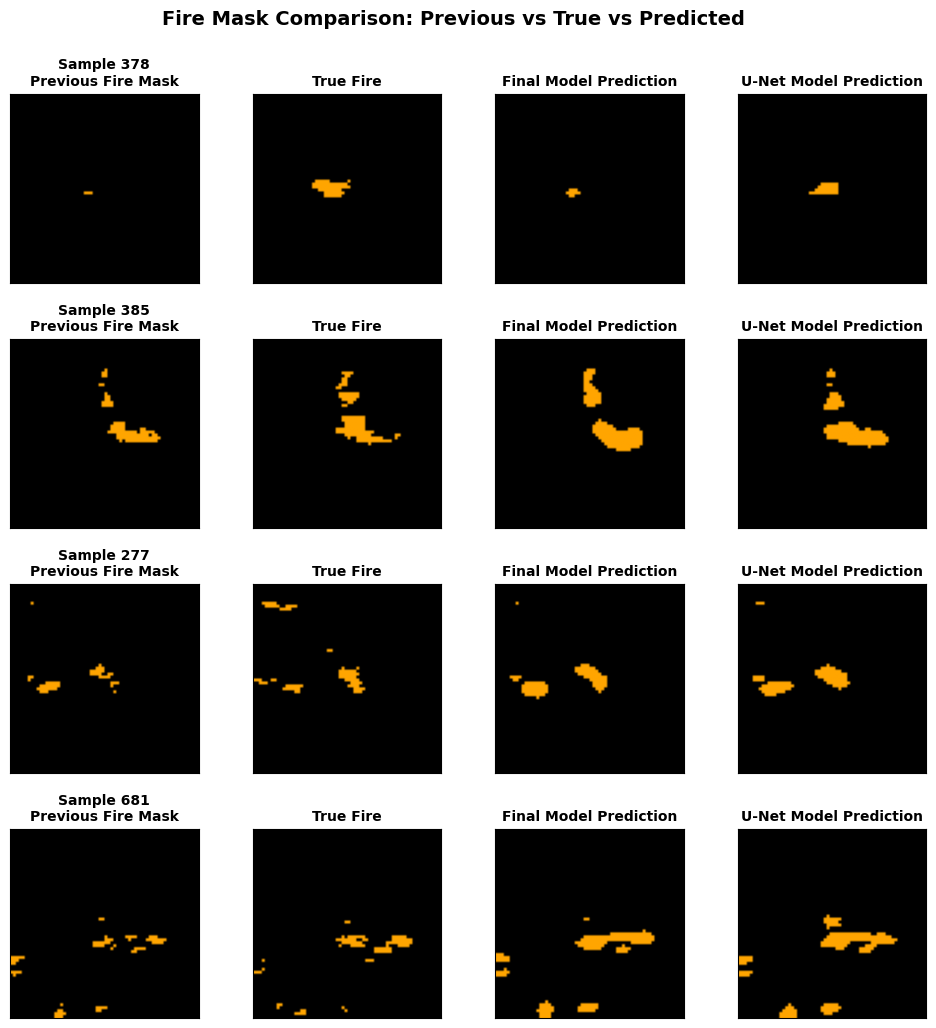

In [108]:
# Initialize parameters
num_samples = 4
custom_cmap = ListedColormap(["black", "orange"])  # Black: No Fire, Orange: Fire

# Randomly select samples from test data
random_indices = np.random.choice(input_test.shape[0], num_samples, replace=False)

# Model predictions for selected samples
predictions_final = final_model.predict(input_test[random_indices])
predictions_unet = unet_final_model.predict(input_test[random_indices])

# Ensure predictions match label dimensions
assert predictions_final.shape == (num_samples, 64, 64, 1), "Incorrect prediction dimensions!"
assert predictions_unet.shape == (num_samples, 64, 64, 1), "Incorrect prediction dimensions!"

# Create plot for visualization
fig, axes = plt.subplots(num_samples, 4, figsize=(12, num_samples*3))
plt.subplots_adjust(hspace=0.3)

for i, idx in enumerate(random_indices):
    # Column 1: Last input feature (Previous Fire Mask)
    axes[i,0].imshow(input_test[idx,:,:,-1], cmap=custom_cmap)
    axes[i,0].set_title(f"Sample {idx}\nPrevious Fire Mask", fontsize=10, weight="bold")

    # Column 2: Ground truth label (Next day Fire Mask)
    axes[i,1].imshow(label_test[idx,:,:,0], cmap=custom_cmap)
    axes[i,1].set_title("True Fire", fontsize=10, weight="bold")

    # Column 3: Final model prediction
    axes[i,2].imshow(predictions_final[i,:,:,0], cmap=custom_cmap)
    axes[i,2].set_title("Final Model Prediction", fontsize=10, weight="bold")

    # Column 4: U-Net model prediction
    axes[i,3].imshow(predictions_unet[i,:,:,0], cmap=custom_cmap)
    axes[i,3].set_title("U-Net Model Prediction", fontsize=10, weight="bold")

    for ax in axes[i]:
        ax.set_xticks([])
        ax.set_yticks([])

plt.suptitle("Fire Mask Comparison: Previous vs True vs Predicted", y=0.95, fontsize=14, fontweight='bold')
plt.show()

---------------

### *Feature Analysis and Grad-CAM Visualization for Model Interpretability*


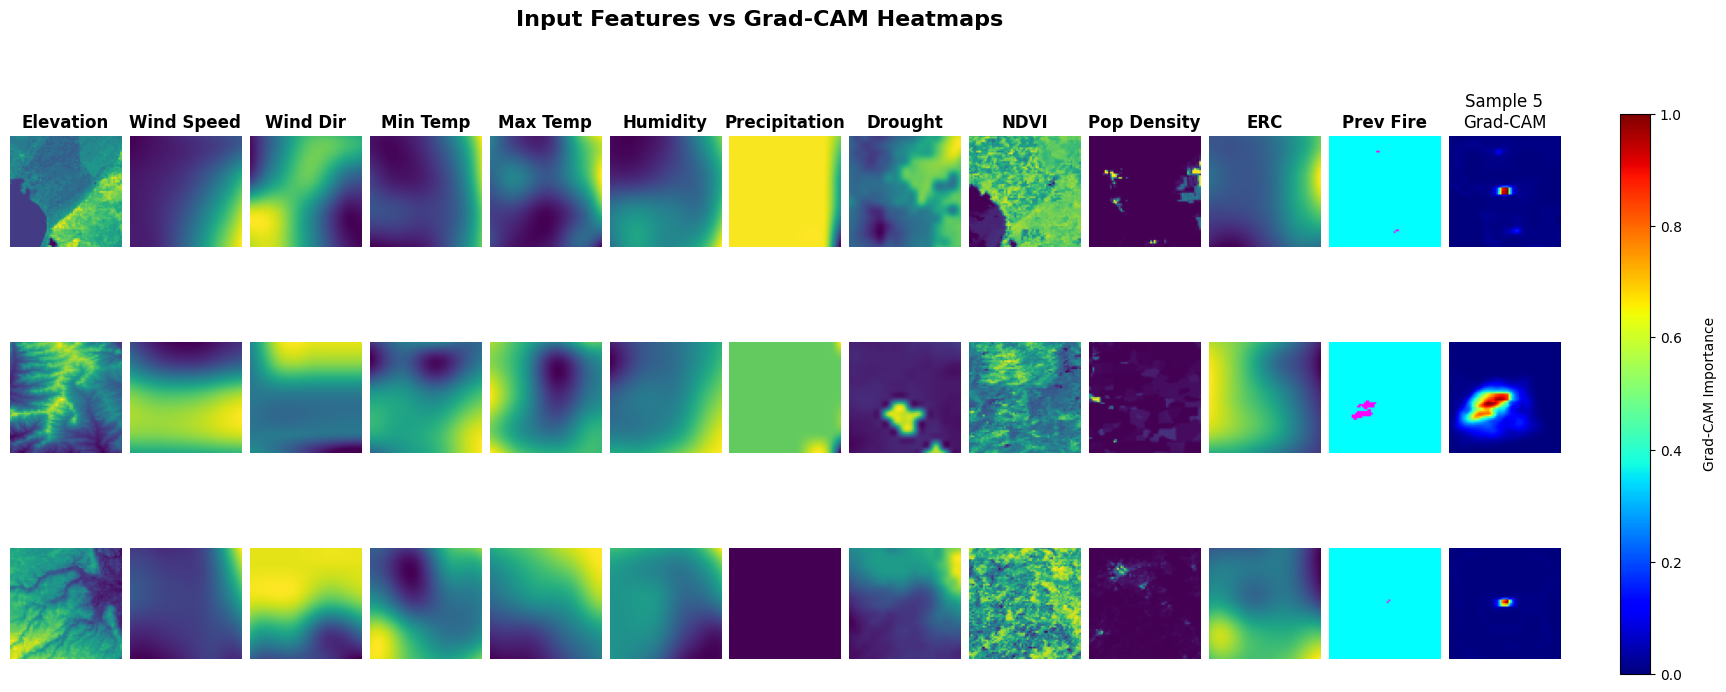

In [237]:
sample_indices = [5, 10, 25]

# Feature names to show above each column
name_list = [
    'Elevation', 'Wind Speed', 'Wind Dir', 'Min Temp', 'Max Temp',
    'Humidity', 'Precipitation', 'Drought', 'NDVI', 'Pop Density',
    'ERC', 'Prev Fire']

# Create a figure with 3 rows (samples) and 13 columns (12 features + 1 Grad-CAM)
fig, axes = plt.subplots(3, 13, figsize=(20, 8))
plt.subplots_adjust(wspace=0.08, hspace=0.01)

# To hold one heatmap image for colorbar reference
heatmap_for_colorbar = None

# Loop through selected samples
for row_idx, idx in enumerate(sample_indices):
    sample = input_test[idx]  # shape: (64, 64, 12)

    # Plot the 12 feature channels
    for ch in range(12):
        ax = axes[row_idx, ch]
        ax.imshow(sample[:, :, ch], cmap='viridis' if ch != 11 else 'cool')
        
        # Show feature name only for the top row
        if row_idx == 0:
            ax.set_title(name_list[ch], fontsize=12, fontweight='bold')
        
        ax.axis('off')

    # Plot Grad-CAM heatmap
    ax = axes[row_idx, 12]
    heatmap = get_gradcam_heatmap(unet_final_model, sample, last_conv_layer_name="conv2d_50")
    im = ax.imshow(heatmap, cmap='jet', vmin=0.0, vmax=1.0)

    # Title only for top row
    if row_idx == 0:
        ax.set_title(f"Sample {idx}\nGrad-CAM", fontsize=12)
    
    ax.axis('off')

    # Save heatmap for global colorbar
    if heatmap_for_colorbar is None:
        heatmap_for_colorbar = im

# Add one global colorbar on the right
cbar_ax = fig.add_axes([0.93, 0.15, 0.015, 0.7])
cbar = fig.colorbar(heatmap_for_colorbar, cax=cbar_ax)
cbar.set_label('Grad-CAM Importance', fontsize=10, labelpad=15)

# Add overall title
plt.suptitle("Input Features vs Grad-CAM Heatmaps", y=0.98, fontsize=16, fontweight='bold')
plt.show()


---------------

### *Feature Impact Analysis on SHAP Algorithm*


In [201]:
# Use test set for evaluation
X_base = input_test.copy()
y_true = label_test.copy()

# Get model baseline prediction
y_pred_base = unet_final_model.predict(X_base, verbose=0)
y_pred_base_bin = (y_pred_base > 0.5).astype(np.uint8)

# Calculate baseline metrics
baseline_recall = recall_score(y_true.flatten(), y_pred_base_bin.flatten())
baseline_precision = precision_score(y_true.flatten(), y_pred_base_bin.flatten())

# Feature names
feature_names = [
    'Elevation', 'Wind Speed', 'Wind Dir', 'Min Temp', 'Max Temp',
    'Humidity', 'Precipitation', 'Drought', 'NDVI', 'Pop Density',
    'ERC', 'Prev Fire']

# Store performance drop per feature
recall_drop = []
precision_drop = []

for i in range(12):
    print(f"Evaluating feature {i+1}: {feature_names[i]}")

    # Copy test data
    X_perturbed = X_base.copy()

    # Perturb feature i by setting it to zero
    X_perturbed[..., i] = 0.0

    # Predict with perturbed input
    y_pred_perturbed = unet_final_model.predict(X_perturbed, verbose=0)
    y_pred_perturbed_bin = (y_pred_perturbed > 0.5).astype(np.uint8)

    # Compute new metrics
    recall = recall_score(y_true.flatten(), y_pred_perturbed_bin.flatten())
    precision = precision_score(y_true.flatten(), y_pred_perturbed_bin.flatten())

    # Calculate drop from baseline
    recall_drop.append(baseline_recall - recall)
    precision_drop.append(baseline_precision - precision)


Evaluating feature 1: Elevation
Evaluating feature 2: Wind Speed
Evaluating feature 3: Wind Dir
Evaluating feature 4: Min Temp
Evaluating feature 5: Max Temp
Evaluating feature 6: Humidity
Evaluating feature 7: Precipitation
Evaluating feature 8: Drought
Evaluating feature 9: NDVI
Evaluating feature 10: Pop Density
Evaluating feature 11: ERC
Evaluating feature 12: Prev Fire


---------------

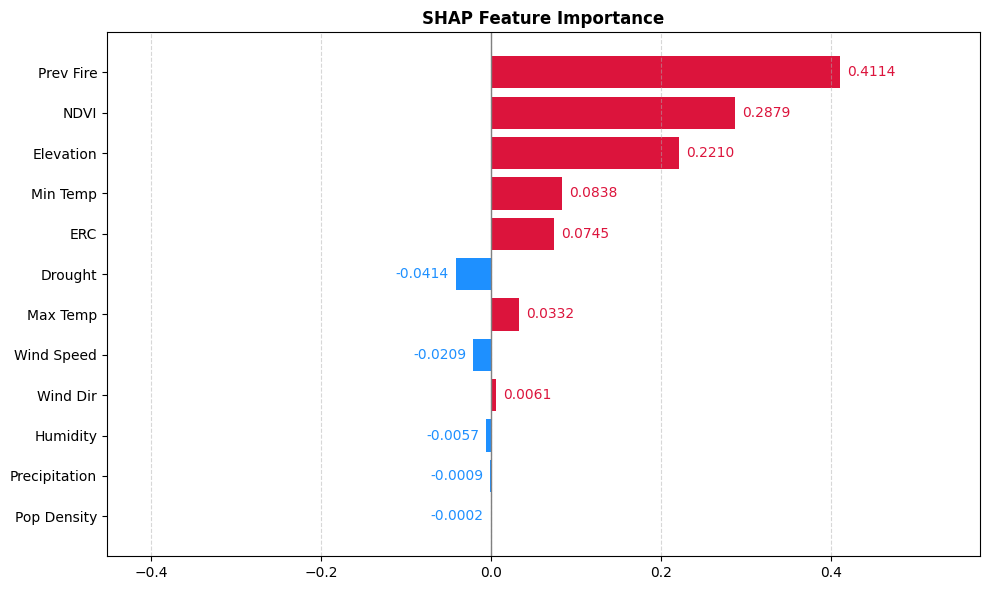

In [233]:
# Sort importance and features
importance = np.array(recall_drop)
sorted_idx = np.argsort(np.abs(importance))[::-1]
importance_sorted = importance[sorted_idx]
feature_names_sorted = np.array(feature_names)[sorted_idx]

# Define custom colors: light red for positive, light blue for negative
colors = ['crimson' if val > 0 else 'dodgerblue' for val in importance_sorted]

# Create horizontal bar plot
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(
    range(len(importance_sorted)),
    importance_sorted,
    color=colors)

# Ensure 0 is centered by setting symmetric x-limits
max_abs_val = np.max(np.abs(importance_sorted))
ax.set_xlim(-max_abs_val * 1.1, max_abs_val * 1.4)

# Add vertical line at zero
ax.axvline(0, color='gray', linewidth=1)

# Axis labels and formatting
ax.set_yticks(range(len(importance_sorted)))
ax.set_yticklabels(feature_names_sorted)
ax.set_xlabel("")
ax.set_title("SHAP Feature Importance", fontweight='bold')
ax.invert_yaxis()
ax.grid(axis='x', linestyle='--', alpha=0.5)

# Add text labels beside bars with color matching the bar
for i, bar in enumerate(bars):
    width = bar.get_width()
    alignment = 'left' if width >= 0 else 'right'
    offset = 0.02 * max_abs_val
    ax.text(
        bar.get_x() + width + (offset if width >= 0 else -offset),
        bar.get_y() + bar.get_height() / 2,
        f"{importance_sorted[i]:.4f}",
        ha=alignment,
        va='center',
        fontsize=10,
        color=colors[i])

plt.tight_layout()
plt.show()


---------------

### *Performance & Metrices Comparison*

In [245]:
# Initialize pretty table with wider formatting
table = PrettyTable()
table.field_names = ["Metric", "CNN Model", "U-Net Model"]

# Define evaluation metrics
metrics = ["Loss", "Accuracy", "Recall", "Precision", "AUC"]
final_model_results = [test_results[0], test_results[1], test_results[2], test_results[3], roc_auc_final]
unet_model_results = [results[0], results[1], results[2], results[3], roc_auc_unet]

# Add rows to table with more spacing
for i in range(len(metrics)):
    table.add_row([metrics[i], f"{final_model_results[i]:.4f}".center(15), f"{unet_model_results[i]:.4f}".center(15)])

# Adjust column widths
table.align["Metric"] = "l"
table.align["Final Model"] = "c"  
table.align["U-Net Model"] = "c"

# Increase width by adding extra padding
table.max_width = 30

# Apply green color styling
print("\n" + "\033[92m" + str(table) + "\033[0m" + "\n")


+-----------+-----------------+-----------------+
| Metric    |    CNN Model    |   U-Net Model   |
+-----------+-----------------+-----------------+
| Loss      |      0.0836     |      0.0708     |
| Accuracy  |      0.9843     |      0.9855     |
| Recall    |      0.3619     |      0.4309     |
| Precision |      0.3584     |      0.4106     |
| AUC       |      0.9189     |      0.9476     |
+-----------+-----------------+-----------------+



In [248]:
gc.collect()

95272

---------------

# END ^^